# The Vision Transformer in expex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidesartor/expex/blob/main/examples/notebooks/vit.ipynb)

> **Python 3.14+ is needed.** expex requires Python 3.14, and Colab's hosted runtimes ship
> Python 3.12 (the 2026.01 runtime has 3.12.12), so on a hosted runtime the setup cell stops
> with a message. To run this notebook in Colab, start Jupyter on Python 3.14 on your machine
> and use *Connect → Connect to a local runtime*
> ([how](https://github.com/davidesartor/expex/blob/main/examples/notebooks/README.md#running-in-colab)),
> or open it in Jupyter directly. If *Runtime → Change runtime type* offers a runtime with
> Python 3.14, that works too. The outputs below are from a run on a CPU.

A port of `vit_jax/models_vit.py` from
[google-research/vision_transformer](https://github.com/google-research/vision_transformer)
(Flax) to expex: [`examples/vit/vit.py`](../vit/vit.py), 85 lines of code against 183. An image
is cut into patches by naming the axes it is split into, heads are contracted by axis name,
and the image size is in the model's signature (`f32[GH * P, GW * Q, C]`).

This notebook runs it on a small model, shows what expex reads from the annotations, checks it
against the original's saved outputs, and times it.

In [1]:
# Setup: install expex from GitHub (or use a local checkout) and fetch the examples.
EXPEX_REF = "main"  # the branch or tag of github.com/davidesartor/expex to install

import os, pathlib, subprocess, sys

if sys.version_info < (3, 14):
    raise RuntimeError(
        f"expex needs Python 3.14+, and this runtime has Python {sys.version.split()[0]}: "
        "connect to a local runtime with Python 3.14 (see the note at the top of the notebook)"
    )


def find_checkout() -> pathlib.Path | None:
    """A local checkout of expex: $EXPEX_REPO, or a folder above the working directory."""
    if os.environ.get("EXPEX_REPO"):
        return pathlib.Path(os.environ["EXPEX_REPO"]).resolve()
    for folder in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (folder / "src" / "expex").is_dir() and (folder / "examples").is_dir():
            return folder
    return None


def run(*cmd: str) -> None:
    subprocess.run(cmd, check=True)


REPO = find_checkout()
if REPO is None:  # Colab, or a notebook opened on its own: install from GitHub
    REPO = pathlib.Path("expex").resolve()
    run(sys.executable, "-m", "pip", "install", "-q", f"git+https://github.com/davidesartor/expex@{EXPEX_REF}")
    if not REPO.exists():  # the examples and the reference outputs of the originals
        run("git", "clone", "-q", "--depth", "1", "--branch", EXPEX_REF, "https://github.com/davidesartor/expex", str(REPO))
else:
    try:
        import expex  # noqa: F401
    except ImportError:
        run(sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO))
sys.path.insert(0, str(REPO / "examples" / "vit"))
print("Python", sys.version.split()[0], "| examples from", REPO.name)

Python 3.14.6 | examples from vigilant-barnacle


In [2]:
import inspect
import time

import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np

import expex
import vit  # examples/vit/vit.py
from vit import ViT

print(inspect.getsource(vit.PatchEmbed))
print(inspect.getsource(vit.ViT.__call__))

@expex.struct
class PatchEmbed[P, Q, C, D]:
    """Each P x Q patch of C channels mapped to width D (the original's strided convolution)."""

    kernel: f32[P, Q, C, D] = conv
    bias: f32[D] = 0.0

    def __call__[Hpx, Wpx](self, image: f32[Hpx, Wpx, C]) -> f32[GH, GW, D]:
        GH, GW = Hpx // P, Wpx // Q  # the grid of patches
        assert Hpx % P == 0 and Wpx % Q == 0
        rows = expex.rearrange(image, to=(GH, P, Wpx, C))  # height split into rows of patches
        patches = expex.rearrange(rows, to=(GH, GW, P, Q, C))  # width split into columns
        return expex.einsum(patches, self.kernel, to=(GH, GW, D)) + self.bias

    def __call__(self, image: f32[GH * P, GW * Q, C]) -> f32[Classes]:
        N = GH * GW
        grid: f32[GH, GW, D] = self.embed(image) + self.pos
        x = jnp.concatenate([(self.cls + self.cls_pos)[None], expex.rearrange(grid, to=(N, D))])  # row by row
        return self.encoder(x)[0] @ self.head + self.head_bias  # read out at the class toke

## The annotated signatures

Every typed function and method in the module, as expex reads it:

In [3]:
def signature(f):
    owner = f.name.rpartition(".")[0]
    return f"{owner}.{f.signature}" if owner else f.signature


for report in expex.prove(vit):
    print(signature(report.fn))

LayerNorm.__call__(self: LayerNorm, x: f32[D]) -> f32[D]
PatchEmbed.__call__[Hpx, Wpx](self: PatchEmbed, image: f32[Hpx, Wpx, C]) -> f32[Hpx // P, Wpx // Q, D]
Attention.__call__[T, S](self: Attention, x: f32[T, D]) -> f32[T, D]
MLP.__call__(self: MLP, x: f32[D]) -> f32[D]
Block.__call__[T](self: Block, x: f32[T, D]) -> f32[T, D]
Encoder.__call__[T](self: Encoder, x: f32[T, D]) -> f32[T, D]
ViT.__call__(self: ViT, image: f32[GH * P, GW * Q, C]) -> f32[Classes]
ViT.loss(self: ViT, image: f32[GH * P, GW * Q, C], label: Int[()]) -> f32[()]


`expex.debug.shapes` shows the shape of every line of the attention, for all sizes at once:

In [4]:
print(expex.debug.shapes(vit.Attention.__call__))

__call__[T, S](self: Attention, x: f32[T, D]) -> f32[T, D]   [symbolic D, H, K, T]
   77 |     def __call__[T, S](self, x: f32[T, D]) -> f32[T, D]:
   78 |         keys: f32[S, D] = x  # the same tokens, attended to                # keys: f32[T, D]
   79 |         q: f32[T, H, K] = (expex.einsum(x, self.wq, to=(T, H, K)) + self.bq) / jnp.sqrt(K)   # q: f32[T, H, K]
   80 |         k: f32[S, H, K] = expex.einsum(keys, self.wk, to=(S, H, K)) + self.bk   # k: f32[T, H, K]
   81 |         v: f32[S, H, K] = expex.einsum(keys, self.wv, to=(S, H, K)) + self.bv   # v: f32[T, H, K]
   82 |         weights: f32[H, T, S] = jax.nn.softmax(expex.einsum(q, k, to=(H, T, S)), axis=S)   # weights: f32[H, T, T]
   83 |         out = expex.einsum(weights, v, to=(T, H, K))                       # out: f32[T, H, K]
   84 |         return expex.einsum(out, self.wo, to=(T, D)) + self.bo             # -> f32[T, D]


## Run it

ViT-Ti's width (192, 3 heads of 64, MLP width 768) with 2 of its 12 layers, on 32 x 32 images
in 4 x 4 patches: an 8 x 8 grid. The model is written for one image; a batch maps over it.

In [5]:
model = ViT(jr.key(0), GH=8, GW=8, P=4, Q=4, C=3, D=192, H=3, K=64, F=768, Classes=10, layers=2)
images = jr.normal(jr.key(1), (16, 32, 32, 3))
labels = jr.randint(jr.key(2), (16,), 0, 10)


@jax.jit  # the model's call checks the images against its sizes
def step(model: ViT, images: jax.Array, labels: jax.Array) -> tuple[ViT, jax.Array]:
    loss, grads = jax.value_and_grad(lambda m: m.loss(images, labels).mean())(model)
    return jax.tree.map(lambda p, g: p - 0.05 * g, model, grads), loss


print("logits", model(images[0]).shape, "for one image;", model(images).shape, "for the batch")
for i in range(5):
    model, loss = step(model, images, labels)
    print(f"step {i}: loss {float(loss):.4f}")

logits (10,) for one image; (16, 10) for the batch


step 0: loss 2.3026
step 1: loss 1.7261
step 2: loss 1.4292


step 3: loss 1.5661
step 4: loss 1.1059


## What the annotations give

**Proofs** for every size, without data:

In [6]:
expex.prove(vit)

ok    vit.LayerNorm.__call__
ok    vit.PatchEmbed.__call__
ok    vit.Attention.__call__
ok    vit.MLP.__call__
ok    vit.Block.__call__
ok    vit.Encoder.__call__
ok    vit.ViT.__call__
ok    vit.ViT.loss

8 functions: 8 proved

**A summary** of the model, and its **cost** as formulas in the sizes, then for ViT-B/16 on
224 x 224 images:

In [7]:
expex.summary(model)

ViT   (GH=8, GW=8, P=4, Q=4, C=3, D=192, H=3, K=64, F=768, Classes=10, L=2)
module         class                                   params  formula                                                                                        bytes   flops  flops formula
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
embed          PatchEmbed[P=4, Q=4, C=3, D=192]         9,408  P·Q·C·D + D                                                                                  37.6 kB          2·floordiv(Hpx, P)·floordiv(Wpx, Q)·P·Q·C·D + floordiv(Hpx, P)·floordiv(Wpx, Q)·D
  kernel       f32[P, Q, C, D]                          9,216  P·Q·C·D                                                                                      36.9 kB
  bias         f32[D]                                     192  D                                                                   

In [8]:
print(expex.cost(ViT.__call__))
print(expex.cost(ViT.__call__, GH=14, GW=14, P=16, Q=16, C=3, D=768, H=12, K=64, F=3072, Classes=1000, layers=12))

ViT.__call__   (sizes: GH, GW, P, Q, C, D, H, K, F, Classes, L)
  flops        4·GH²·GW²·H·K·L + 8·GH·GW·D·H·K·L + 5·GH²·GW²·H·L + 2·GH·GW·P·Q·C·D + 12·GH·GW·H·K·L + 4·GH·GW·D·F·L + 22·GH·GW·D·L + 11·GH·GW·H·L + 9·GH·GW·F·L + 8·D·H·K·L + 12·GH·GW·L + 11·GH·GW·D + 8·H·K·L + 4·D·F·L + 22·D·L + 9·F·L + 6·GH·GW + 6·H·L + 2·D·Classes + 17·L + 10·D + Classes + 8
  parameters   4·D·H·K·L + P·Q·C·D + 3·H·K·L + 2·D·F·L + GH·GW·D + 6·D·L + F·L + D·Classes + 5·D + Classes
  largest      f32[H,GH*GW + 1,GH*GW + 1] (GH²·GW²·H + 2·GH·GW·H + H elements)
  note: L = len(self.encoder.layers)
ViT.__call__   (sizes: GH=14, GW=14, P=16, Q=16, C=3, D=768, H=12, K=64, F=3072, Classes=1000, L=12)
  flops        35269885620   = 35.3 GFLOP
  parameters   86567656   = 86.6 M
  largest      f32[H,GH*GW + 1,GH*GW + 1] (465708 elements)
  note: L = len(self.encoder.layers)


**A diagram** drawn from the code. When you run the notebook it is an interactive page: click a
call to open it.

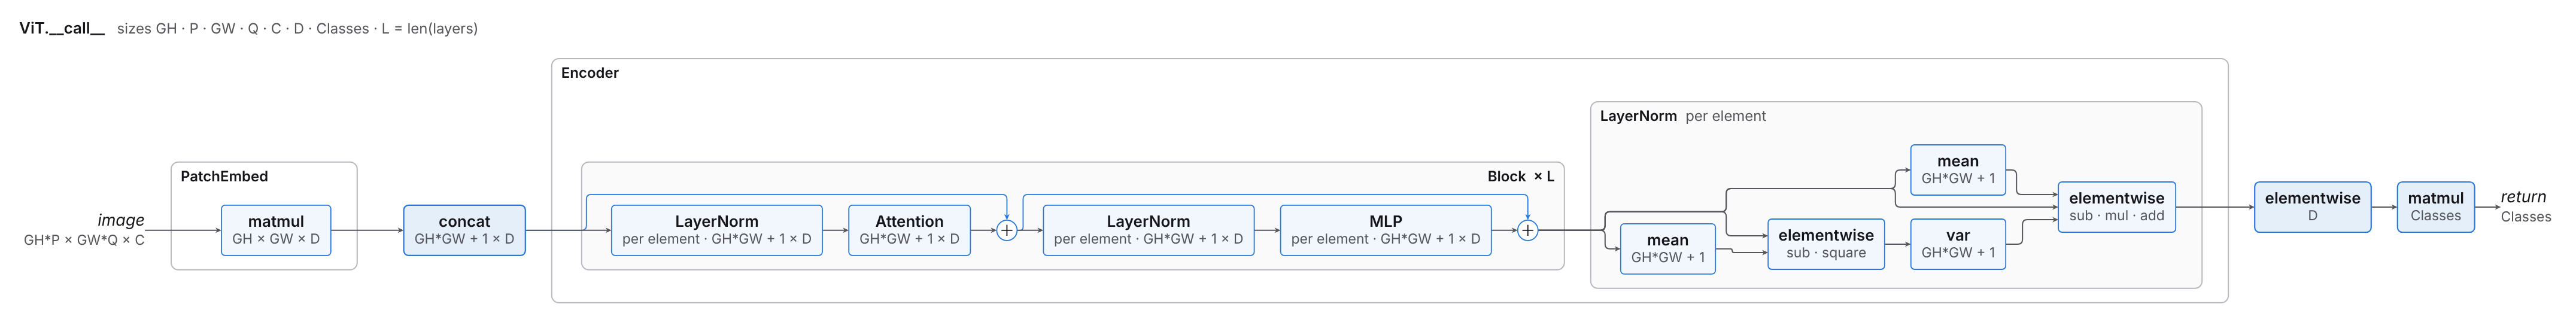

In [9]:
expex.diagram(ViT.__call__, depth=3)

**`expex.inspect`**: every tool in one page, with activations and gradients of the loss.

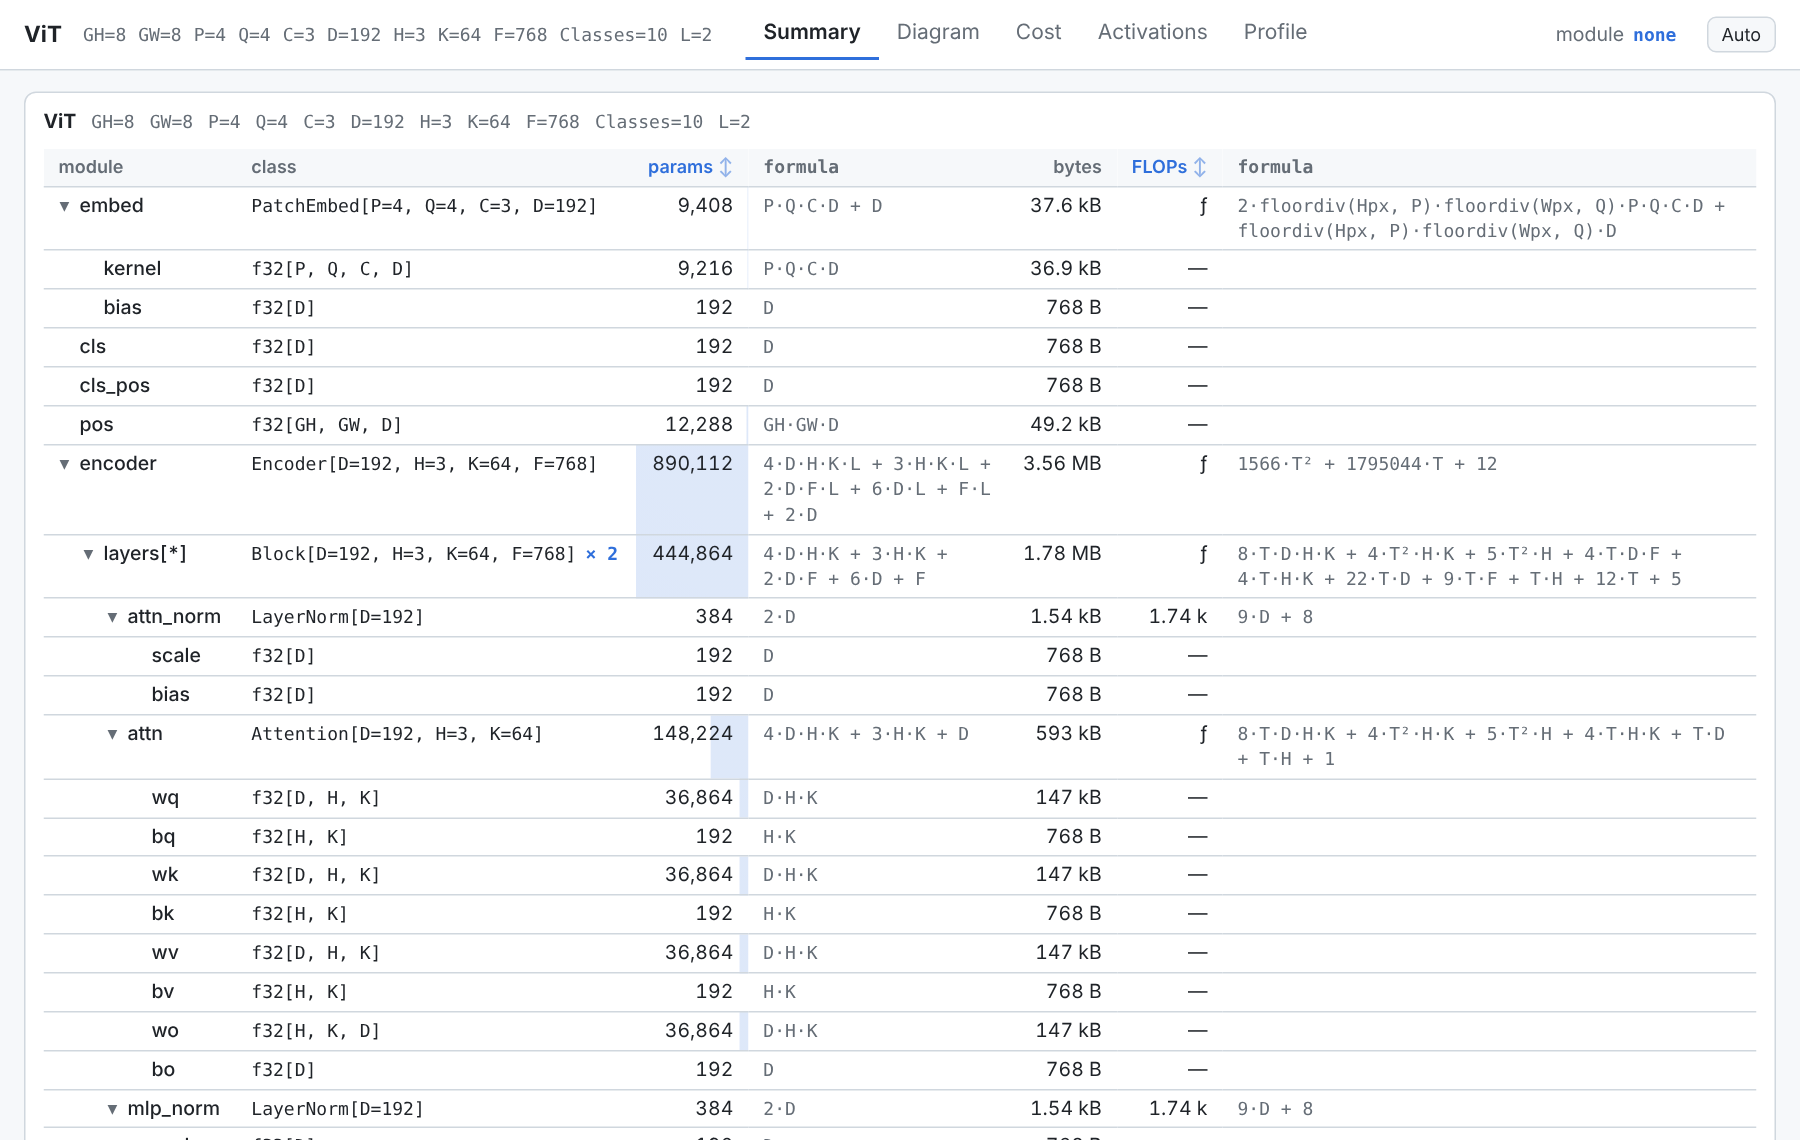

In [10]:
expex.inspect(model, images[0], loss=lambda m, x: m.loss(x, labels[0]))

## A shape error

The model's signature fixes the image size. A 32 x 36 image says which size it disagrees with,
and the patch embedding alone, which takes any grid of whole patches, refuses a width that is
not a multiple of the patch:

In [11]:
try:
    model(jnp.ones((32, 36, 3)))
except expex.ShapeError as e:
    error = e
error

ShapeError: ViT.__call__(): argument `image` does not match its annotation.

    declared  image: f32[GH * P, GW * Q, C]
    received         f32[32, 36, 3]

    axis 1 should be GW * Q = 32 (with GW=8, Q=4), but is 36.

    __call__(self: ViT, image: f32[GH * P, GW * Q, C]) -> f32[Classes]
    defined at examples/vit/vit.py:133
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex101


In [12]:
try:
    model.embed(jnp.ones((32, 30, 3)))
except expex.ShapeError as e:
    error = e
error

ShapeError: PatchEmbed.__call__(): constraint `Wpx % Q == 0` is violated (Q=4, Wpx=30).

    __call__[Hpx, Wpx](self: PatchEmbed, image: f32[Hpx, Wpx, C]) -> f32[Hpx // P, Wpx // Q, D]
    defined at examples/vit/vit.py:56
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex104


## Activations and gradients, layer by layer

In [13]:
watch = expex.debug.watch(lambda m: m.loss(images[0], labels[0]), model)
print(f"{len(watch.rows)} calls, {len(watch.flagged)} flagged")
watch

15 calls, 0 flagged


watch <lambda>: loss 0.998018, 15 calls, 0 flagged  (grad_ratio=100.0, growth=10.0)
                                                                    ─────────────────output────────────────  ───────────────d loss / d output───────────────
  call                                          shape           ×n       mean    std  |max|    rms  nan/inf       mean       std    |max|       rms  nan/inf  flags
  ViT.loss                                      f32              1      0.998      0  0.998  0.998                   1         0        1         1
    ViT.__call__                                f32[10]          1  -5.96e-08  0.657   1.58  0.657            5.96e-09     0.213    0.631     0.213
      embed.__call__                            f32[8, 8, 192]   1   -0.00521      1   3.99      1            2.43e-12   0.00242    0.049   0.00242
      encoder.__call__                          f32[65, 192]     1   -5.5e-06      1   4.08      1           -5.73e-10   0.00104   0.0245   0.00104
   

## Against the original

`tests/data/vit_reference.npz` holds the parameters of a small `VisionTransformer` built by the
unmodified original, its logits on two 32 x 24 images in 4 x 2 patches, and a loss with its
gradients. `compare.py` loads those parameters into the port and measures the largest
differences:

In [14]:
import compare  # examples/vit/compare.py

reference = dict(np.load(REPO / "tests" / "data" / "vit_reference.npz"))
for name, diff in compare.compare(reference).items():
    print(f"{name:28} {diff:.3g}")

logits                       4.91e-07
loss                         1.19e-07
gradients (relative)         9.33e-07
key-bias gradients (zero)    2.89e-08


## Speed

Compiled forward pass and gradients at the size above. Timings depend on the machine, so
compare them only with each other. The repository's [benchmarks/](../../benchmarks/) compare
the port with the original on CPU (best of 25 rounds, median in brackets): slightly slower,
forward 0.92x (0.96x), gradients 0.93x (1.01x).

In [15]:
def bench(f, *args, n=20):
    """Median seconds per call, after a first call that compiles."""
    jax.block_until_ready(f(*args))
    times = []
    for _ in range(n):
        start = time.perf_counter()
        jax.block_until_ready(f(*args))
        times.append(time.perf_counter() - start)
    return float(np.median(times))


forward = jax.jit(lambda m, x: m(x))
grads = jax.jit(jax.grad(lambda m, x, y: m.loss(x, y).mean()))
print(f"forward, 16 images   {bench(forward, model, images) * 1e3:7.2f} ms")
print(f"gradients, 16 images {bench(grads, model, images, labels) * 1e3:7.2f} ms")

forward, 16 images     29.72 ms


gradients, 16 images  102.21 ms
